In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:/Users/Bhumika Chandan/Downloads/Dataset .csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
print(df[["Has Online delivery", "Aggregate rating"]].head())

  Has Online delivery  Aggregate rating
0                  No               4.8
1                  No               4.5
2                  No               4.4
3                  No               4.9
4                  No               4.8


In [5]:
print(df["Has Online delivery"].value_counts())

Has Online delivery
No     7100
Yes    2451
Name: count, dtype: int64


In [6]:
delivery_counts = df["Has Online delivery"].value_counts()

total_restaurants = delivery_counts.sum()

delivery_percentage = (delivery_counts / total_restaurants) * 100

delivery_result = pd.DataFrame({
    "Online Delivery": delivery_counts.index,
    "Restaurant Count": delivery_counts.values,
    "Percentage": delivery_percentage.values.round(2)
})

display(delivery_result)

,Online Delivery,Restaurant Count,Percentage
0,No,7100,74.34
1,Yes,2451,25.66


In [7]:
rated_df = df[df["Aggregate rating"] > 0]

average_ratings = rated_df.groupby(
    "Has Online delivery"
)["Aggregate rating"].mean()

print("Average Ratings:")
display(average_ratings.round(2))

Average Ratings:


Has Online delivery
No     3.47
Yes    3.38
Name: Aggregate rating, dtype: float64

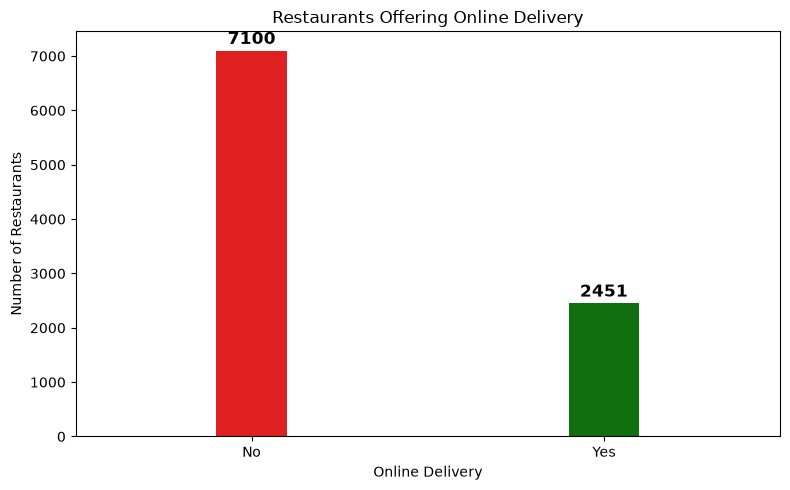

In [18]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    hue=delivery_counts.index,
    palette={"No": "red", "Yes": "green"},
    width=0.2,
    legend=False
)

# Add restaurant count labels above bars
for i, value in enumerate(delivery_counts.values):
    ax.text(
        i,
        value + 50,
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.title("Restaurants Offering Online Delivery")
plt.xlabel("Online Delivery")
plt.ylabel("Number of Restaurants")

plt.tight_layout()
plt.savefig("Online_Delivery_Distribution.png", dpi=300)
plt.show()

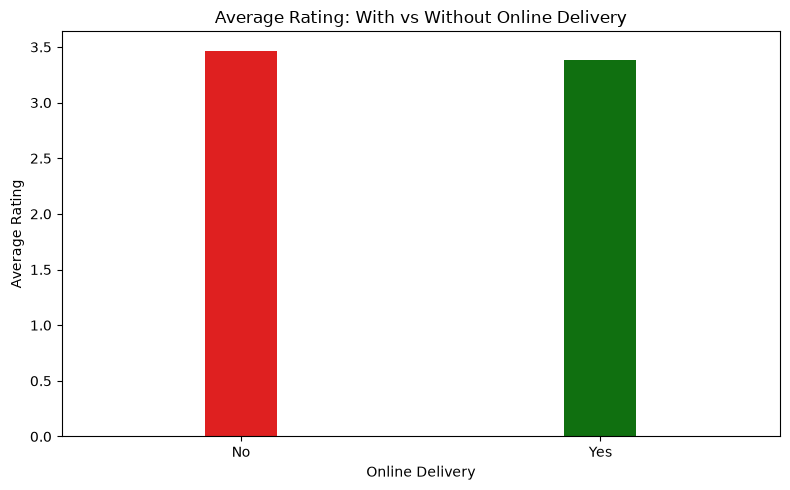

In [15]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=average_ratings.index,
    y=average_ratings.values,
    hue=average_ratings.index,
    palette={"No": "red", "Yes": "green"},
    width=0.2,
    legend=False
)

plt.title("Average Rating: With vs Without Online Delivery")
plt.xlabel("Online Delivery")
plt.ylabel("Average Rating")

plt.tight_layout()
plt.savefig("Online_Delivery_Rating_Comparison.png", dpi=300)
plt.show()

In [19]:
delivery_result.to_csv(
    "Online_Delivery_Percentage.csv",
    index=False
)

average_ratings.to_csv(
    "Online_Delivery_Average_Ratings.csv"
)

print("Task 4 completed successfully!")

Task 4 completed successfully!
